In [3]:
import re
import nltk

nltk.download("punkt")
nltk.download("stopwords")
nltk.download("punkt_tab")

from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.tokenize import sent_tokenize, word_tokenize

text = (
    "Virat Kohli drives the ball elegantly through the covers, sending the "
    "crowd into a roaring frenzy. Fast bowlers charge down the pitch with "
    "blistering pace, attempting to rattle the batter's defense. Strategic "
    "captaincy and sharp field placements dictate the tense battle under the "
    "floodlights. Every single run counts as the chasing team inches closer to "
    "a thrilling victory. Fans across the stadium hold their breath as the "
    "match heads into a dramatic final over."
)

# Step 1: Convert to lowercase and remove punctuation
text_lower = text.lower()
text_clean = re.sub(r"[^\w\s]", "", text_lower)
print("Cleaned Text:\n", text_clean)

# Step 2: Tokenize into words and sentences
sentences = sent_tokenize(text)
print("\nSentences:", sentences)

words = word_tokenize(text_clean)
print("\nWords:", words[:10])

# Step 3: Compare Python split() vs NLTK word_tokenize()
split_tokens = text_clean.split()
nltk_tokens = word_tokenize(text_clean)

print("\nPython split() output:", split_tokens[:10])
print("NLTK word_tokenize() output:", nltk_tokens[:10])

# Step 4: Remove Stopwords
stop_words = set(stopwords.words("english"))
filtered_words = [word for word in nltk_tokens if word not in stop_words]
print("\nFiltered Words (without stopwords):", filtered_words[:10])

# Step 5: Display Word Frequency Distribution
fdist = FreqDist(filtered_words)
print("\nTop 10 Most Frequent Words:")
for word, frequency in fdist.most_common(10):
    print(f"{word}: {frequency}")

Cleaned Text:
 virat kohli drives the ball elegantly through the covers sending the crowd into a roaring frenzy fast bowlers charge down the pitch with blistering pace attempting to rattle the batters defense strategic captaincy and sharp field placements dictate the tense battle under the floodlights every single run counts as the chasing team inches closer to a thrilling victory fans across the stadium hold their breath as the match heads into a dramatic final over

Sentences: ['Virat Kohli drives the ball elegantly through the covers, sending the crowd into a roaring frenzy.', "Fast bowlers charge down the pitch with blistering pace, attempting to rattle the batter's defense.", 'Strategic captaincy and sharp field placements dictate the tense battle under the floodlights.', 'Every single run counts as the chasing team inches closer to a thrilling victory.', 'Fans across the stadium hold their breath as the match heads into a dramatic final over.']

Words: ['virat', 'kohli', 'drives'

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/sujalgupta/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/sujalgupta/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/sujalgupta/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [4]:
import re
import nltk

nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Same cricket paragraph
text = (
    "Virat Kohli drives the ball elegantly through the covers, sending the "
    "crowd into a roaring frenzy. Fast bowlers charge down the pitch with "
    "blistering pace, attempting to rattle the batter's defense. Strategic "
    "captaincy and sharp field placements dictate the tense battle under the "
    "floodlights. Every single run counts as the chasing team inches closer to "
    "a thrilling victory. Fans across the stadium hold their breath as the "
    "match heads into a dramatic final over."
)

# 1. Extract all words with only alphabets using re.findall()
alphabet_words = re.findall(r"\b[A-Za-z]+\b", text.lower())
print("1. Alphabet Words (Sample):\n", alphabet_words[:10])

# 2. Remove stop words using NLTK's stopword list
stop_words = set(stopwords.words("english"))
filtered_words = [word for word in alphabet_words if word not in stop_words]
print("\n2. After Removing Stopwords (Sample):\n", filtered_words[:10])

# 3. Perform stemming with PorterStemmer
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in filtered_words]
print("\n3. Stemmed Words (Sample):\n", stemmed_words[:10])

# 4. Perform lemmatization with WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words]
print("\n4. Lemmatized Words (Sample):\n", lemmatized_words[:10])

# Let's print a side-by-side comparison for some key words from the text
comparison_sample = ["drives", "bowlers", "attempting", "placments", "chasing", "tents", "match"]
print("\n--- Side-by-Side Comparison ---")
print(f"{'Original':<15} | {'Stemmed (Porter)':<20} | {'Lemmatized (WordNet)':<20}")
print("-" * 61)
for w in ["drives", "bowlers", "attempting", "chasing", "stadium", "matches"]:
    print(f"{w:<15} | {stemmer.stem(w):<20} | {lemmatizer.lemmatize(w):<20}")

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/sujalgupta/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/sujalgupta/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/sujalgupta/nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/sujalgupta/nltk_data...


1. Alphabet Words (Sample):
 ['virat', 'kohli', 'drives', 'the', 'ball', 'elegantly', 'through', 'the', 'covers', 'sending']

2. After Removing Stopwords (Sample):
 ['virat', 'kohli', 'drives', 'ball', 'elegantly', 'covers', 'sending', 'crowd', 'roaring', 'frenzy']

3. Stemmed Words (Sample):
 ['virat', 'kohli', 'drive', 'ball', 'elegantli', 'cover', 'send', 'crowd', 'roar', 'frenzi']

4. Lemmatized Words (Sample):
 ['virat', 'kohli', 'drive', 'ball', 'elegantly', 'cover', 'sending', 'crowd', 'roaring', 'frenzy']

--- Side-by-Side Comparison ---
Original        | Stemmed (Porter)     | Lemmatized (WordNet)
-------------------------------------------------------------
drives          | drive                | drive               
bowlers         | bowler               | bowler              
attempting      | attempt              | attempting          
chasing         | chase                | chasing             
stadium         | stadium              | stadium             
matches       

In [5]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 1. Choose 3 short texts (product reviews or news headlines)
texts = [
    "The smartphone battery life is amazing and lasts all day.",
    "Camera quality is terrible and pictures look very blurry.",
    "An absolute masterpiece of a phone with stunning display and smooth performance.",
]

print("--- Original Texts ---")
for i, text in enumerate(texts, 1):
  print(f"Text {i}: {text}")

# 2. Use CountVectorizer to generate the Bag of Words representation
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

# Convert to DataFrame for a clean, readable view
bow_df = pd.DataFrame(
    bow_matrix.toarray(), columns=count_vectorizer.get_feature_names_out()
)
print("\n--- Bag of Words (BoW) Representation ---")
print(bow_df)

# 3. Use TfidfVectorizer to compute TF-IDF scores
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

# Convert to DataFrame
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out()
)
print("\n--- TF-IDF Scores Representation ---")
print(tfidf_df)

# 4. Extract and print top 3 keywords from each text using TF-IDF scores
feature_names = tfidf_vectorizer.get_feature_names_out()
print("\n--- Top 3 Keywords per Text (Interpretation) ---")
for i, row in enumerate(tfidf_matrix.toarray()):
  # Sort feature indices by their TF-IDF score in descending order
  sorted_indices = row.argsort()[::-1]
  top_3_keywords = [feature_names[idx] for idx in sorted_indices[:3]]
  print(f"Text {i + 1} Top Keywords: {top_3_keywords}")

--- Original Texts ---
Text 1: The smartphone battery life is amazing and lasts all day.
Text 2: Camera quality is terrible and pictures look very blurry.
Text 3: An absolute masterpiece of a phone with stunning display and smooth performance.

--- Bag of Words (BoW) Representation ---
   absolute  all  amazing  an  and  battery  blurry  camera  day  display  \
0         0    1        1   0    1        1       0       0    1        0   
1         0    0        0   0    1        0       1       1    0        0   
2         1    0        0   1    1        0       0       0    0        1   

   ...  phone  pictures  quality  smartphone  smooth  stunning  terrible  the  \
0  ...      0         0        0           1       0         0         0    1   
1  ...      0         1        1           0       0         0         1    0   
2  ...      1         0        0           0       1         1         0    0   

   very  with  
0     0     0  
1     1     0  
2     0     1  

[3 rows x 27 c

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Write 2 short texts describing two different technologies
text_ai = (
    "Artificial Intelligence enables machines to learn from data, make decisions, "
    "and perform complex tasks autonomously. It powers modern innovations like "
    "computer vision, natural language processing, and predictive analytics."
)

text_blockchain = (
    "Blockchain is a decentralized, distributed ledger technology that securely "
    "records transactions across multiple computers. It ensures data immutability, "
    "transparency, and trust without requiring a central authority."
)

# 2a. Preprocess and tokenize both texts into sets (for Jaccard Similarity)
set_ai = set(text_ai.lower().split())
set_blockchain = set(text_blockchain.lower().split())

# Calculate Jaccard Similarity
intersection = len(set_ai.intersection(set_blockchain))
union = len(set_ai.union(set_blockchain))
jaccard_sim = intersection / union

print(f"a. Jaccard Similarity: {jaccard_sim:.4f}")

# 2b. Calculate Cosine Similarity using TfidfVectorizer
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([text_ai, text_blockchain])
cosine_sim = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print(f"b. Cosine Similarity: {cosine_sim:.4f}")

a. Jaccard Similarity: 0.0400
b. Cosine Similarity: 0.0821


--- Sentiment Analysis Results ---
Review 1: Polarity=0.75, Subjectivity=0.75 -> Positive
Review 2: Polarity=-1.00, Subjectivity=1.00 -> Negative
Review 3: Polarity=0.33, Subjectivity=0.58 -> Positive
Review 4: Polarity=0.56, Subjectivity=0.62 -> Positive
Review 5: Polarity=-0.35, Subjectivity=0.10 -> Negative


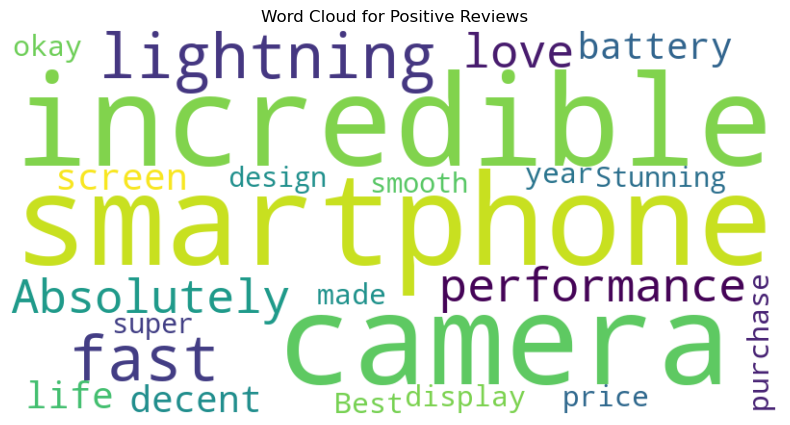

In [9]:
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

# 1. Write a short review for a product or service
reviews = [
    (
        "The smartphone has an incredible camera and lightning-fast"
        " performance! Absolutely love it."
    ),
    "Terrible customer service and the device stopped working after two days.",
    (
        "The battery life is decent, and the screen display is okay for the"
        " price."
    ),
    "Best purchase I've made this year. Stunning design and super smooth.",
    "Completely useless product, broke immediately and a waste of money.",
]

positive_texts = []

print("--- Sentiment Analysis Results ---")
for i, review in enumerate(reviews, 1):
  blob = TextBlob(review)
  polarity = blob.sentiment.polarity
  subjectivity = blob.sentiment.subjectivity

  # 2. Classify reviews into Positive / Negative / Neutral
  if polarity > 0.1:
    sentiment = "Positive"
    positive_texts.append(review)
  elif polarity < -0.1:
    sentiment = "Negative"
  else:
    sentiment = "Neutral"

  print(
      f"Review {i}: Polarity={polarity:.2f}, Subjectivity={subjectivity:.2f} ->"
      f" {sentiment}"
  )

# 3. Create a word cloud using the wordcloud library for all positive reviews
positive_corpus = " ".join(positive_texts)
wordcloud = WordCloud(
    width=800, height=400, background_color="white"
).generate(positive_corpus)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud for Positive Reviews")
plt.show()

In [1]:
import random

# 1. Choose a short paragraph (~100 words) as training data
training_text = (
    "Cricket is a sport that brings millions of fans together across the globe. "
    "Players train rigorously every single day to master batting, bowling, and fielding skills. "
    "Matches can be tense and unpredictable, leading to breathtaking finishes in the final over. "
    "The atmosphere in the stadium becomes electric when boundaries are hit and wickets fall. "
    "True supporters stand by their favorite teams through glorious victories and heartbreaking defeats alike."
)

# 2. Tokenize and build a simple bigram/trigram transition model (Markov Chain)
words = training_text.lower().replace(".", "").replace(",", "").split()

# Build word pairs (Markov chain dictionary)
model = {}
for i in range(len(words) - 1):
    current_word = words[i]
    next_word = words[i + 1]
    if current_word not in model:
        model[current_word] = []
    model[current_word].append(next_word)

print("--- Training Complete (Markov Chain Model) ---")

# 3. Generate 2-3 new lines of text starting from a seed word
seed_word = "cricket"
generated_words = [seed_word]
num_words_to_generate = 15

current = seed_word
for _ in range(num_words_to_generate):
    if current in model:
        # Pick a random next word from the observed transitions
        next_word = random.choice(model[current])
        generated_words.append(next_word)
        current = next_word
    else:
        # Fallback if word isn't in model keys
        current = random.choice(words)
        generated_words.append(current)

# Format into lines
result_text = " ".join(generated_words)
print("\n--- Generated Text ---")
print(result_text)

--- Training Complete (Markov Chain Model) ---

--- Generated Text ---
cricket is a sport that brings millions of fans together across the stadium becomes electric when
